# Seminar 9 · Stable Diffusion 1.5
**Deep Generative Models · MIPT / YSDA (ШАД) · 19 November 2026**

In Imagen, the reverse process produced an image at each resolution. What if we asked a diffusion model to generate the input of an image decoder instead? Follow a photograph of a teapot through training, then generate one from a caption.

Five saved experiment panels can be read offline. To run the experiments, open Colab, select **Runtime → Change runtime type → T4 GPU** (or another GPU), then **Run all**. The first run downloads SD 1.5 weights.

[Open in Google Colab](https://colab.research.google.com/github/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/seminars/seminar9/seminar9.ipynb) · [Course repository](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course)

## Why run diffusion in a latent space?
For a $512 \times 512$ RGB photograph, pixel diffusion tracks $3 \times 512 \times 512$ numbers. The SD 1.5 autoencoder maps it to a grid of $4 \times 64 \times 64$ numbers. This gives 64 times fewer spatial positions and 48 times fewer scalar coordinates. The U-Net revisits this smaller grid at every step. The actual speedup depends on the network and hardware.

**Question.** If the encoder discards a tiny inscription on the teapot, how could we discover that before running diffusion? Encode and decode the reference photo, then inspect the inscription. A generator can invent plausible lettering even when the original letters are lost.

[SD 1.5 model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

## Follow one training pair

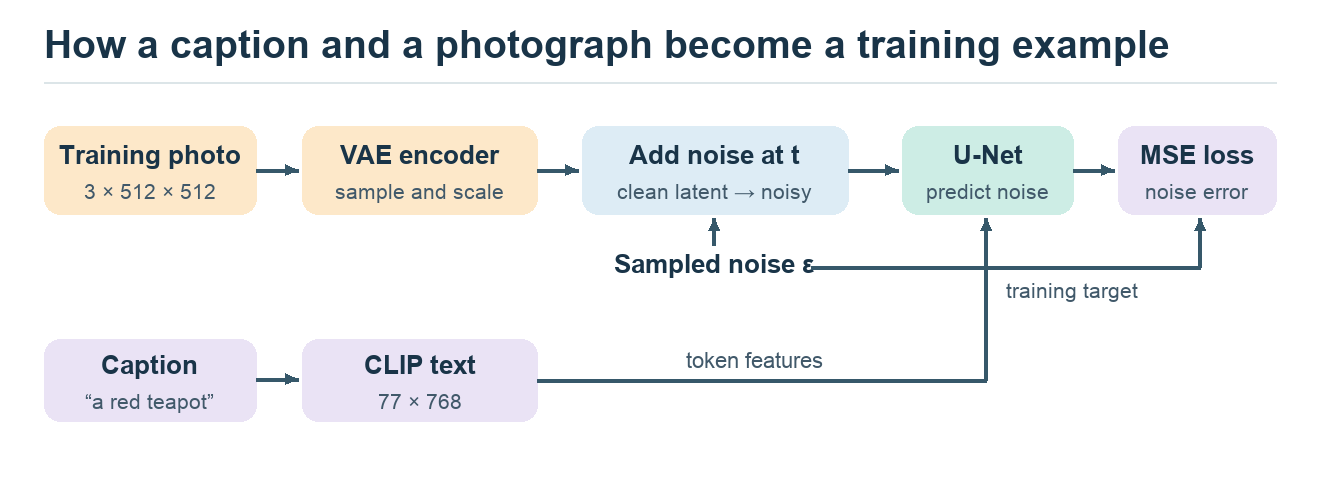

Start with the photograph. The frozen VAE encoder supplies a latent sample, which we scale and corrupt at a randomly chosen time $t$. Follow the caption through frozen CLIP to the U-Net. The U-Net sees the corrupted latent, $t$ and the text features. Follow the sampled noise a second time: the same draw supplies the target for the loss.

[Rombach et al., Fig. 3](https://ommer-lab.com/research/latent-diffusion-models/) · [Jay Alammar, The Illustrated Stable Diffusion](https://jalammar.github.io/illustrated-stable-diffusion/)

### What gets trained?
| Stage | Inputs | Prediction or reconstruction | Learning signal |
|---|---|---|---|
| Autoencoder | Real image $x$ | $D(u)$, where $u$ is sampled from the encoder posterior | Pixel/perceptual reconstruction and a patch discriminator encourage fidelity. KL regularizes the posterior. |
| Latent diffusion | Noisy latent $z_t$, time $t$, caption features $h$ | U-Net output with the shape of $z_t$ | Squared error against the noise used to build $z_t$. The pretrained VAE and CLIP text encoder are frozen. |

For SD 1.5, write $z_0=k u$ with $k$ the checkpoint's VAE scaling factor. For each image-caption pair, sample $t$ and $\epsilon\sim\mathcal N(0,I)$ and form

$$z_t=\sqrt{\bar\alpha_t}\,z_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad
\mathcal L=\mathbb E\big[\|\epsilon-\epsilon_\theta(z_t,t,h)\|_2^2\big].$$

The sampled noise supplies the target. At generation time the trained network estimates it from the current latent. SD 1.5 dropped text conditioning on 10% of examples during its final training stage, enabling both CFG predictions from one model.

[Rombach et al., §3](https://arxiv.org/abs/2112.10752) · [SD 1.5 training details](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

### Load the checkpoint
CLIP encodes the caption, the U-Net predicts noise, DDIM updates the latent and the VAE decodes it. We load the same frozen weights for every run. DDIM with $\eta=0$ makes comparisons reproducible from the same initial latent on the same device.

In [ ]:
%pip -q install diffusers==0.35.2 transformers==4.55.4 accelerate==1.10.1

In [1]:
import torch
from PIL import Image, ImageDraw
from IPython.display import display
from huggingface_hub import snapshot_download
from diffusers import AutoencoderKL, DDIMScheduler, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer
from pathlib import Path

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
dtype = torch.float32 if device == "cpu" else torch.float16
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
root = Path(snapshot_download(
    model_id, revision="451f4fe16113bff5a5d2269ed5ad43b0592e9a14",
    allow_patterns=["tokenizer/*", "text_encoder/config.json", "text_encoder/model.fp16.safetensors",
                    "scheduler/scheduler_config.json", "vae/config.json", "unet/config.json",
                    "vae/*.fp16.safetensors", "unet/*.fp16.safetensors"],
))
weights = dict(variant="fp16", torch_dtype=dtype, use_safetensors=True)
tokenizer = CLIPTokenizer.from_pretrained(root / "tokenizer")
text_encoder = CLIPTextModel.from_pretrained(root / "text_encoder", **weights).to(device).eval()
unet = UNet2DConditionModel.from_pretrained(root / "unet", **weights).to(device).eval()
vae = AutoencoderKL.from_pretrained(root / "vae", **weights).to(device).eval()
scheduler = DDIMScheduler.from_pretrained(root / "scheduler")
assert scheduler.config.prediction_type == "epsilon" and not scheduler.config.clip_sample
print(f"{device} | latent channels: {unet.config.in_channels} | VAE scale: {vae.config.scaling_factor}")

mps | latent channels: 4 | VAE scale: 0.18215


## Inside one U-Net call

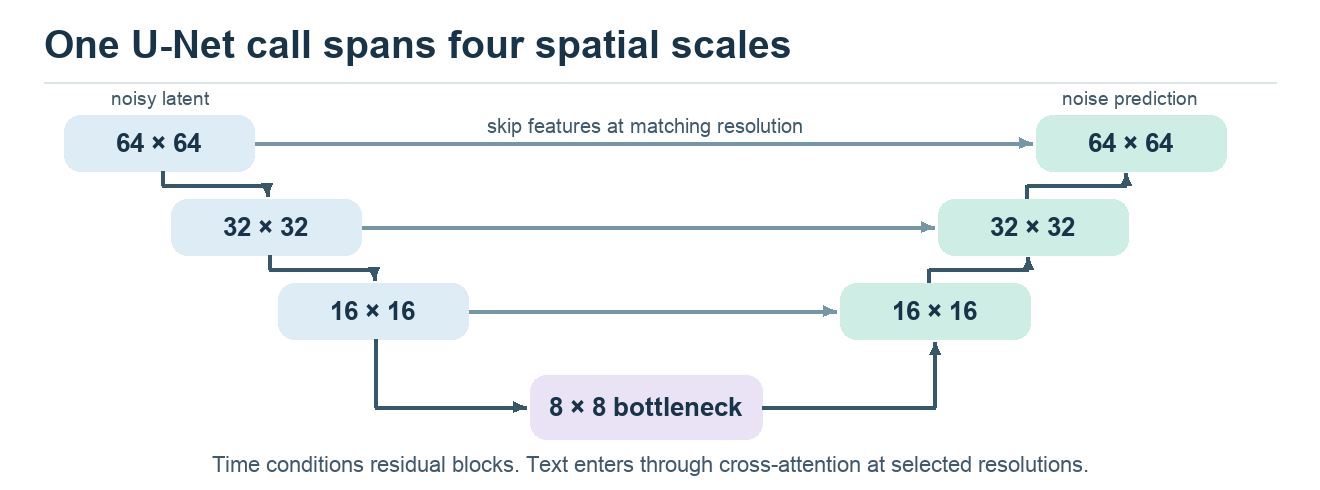

Trace a feature from the upper left down to the bottleneck. Coarser resolutions combine information across distant locations, such as the handle and the spout. Trace the skip connection across the U: the up block receives spatially aligned features from the down path. This helps it recover local detail. A time embedding tells residual blocks how noisy the input is.

The down/up paths run **inside one denoising evaluation**. The next sampler step calls the same U-Net again at a different time.

[SD 1.5 U-Net configuration](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/blob/main/unet/config.json)

### How does “red ceramic” reach a position?

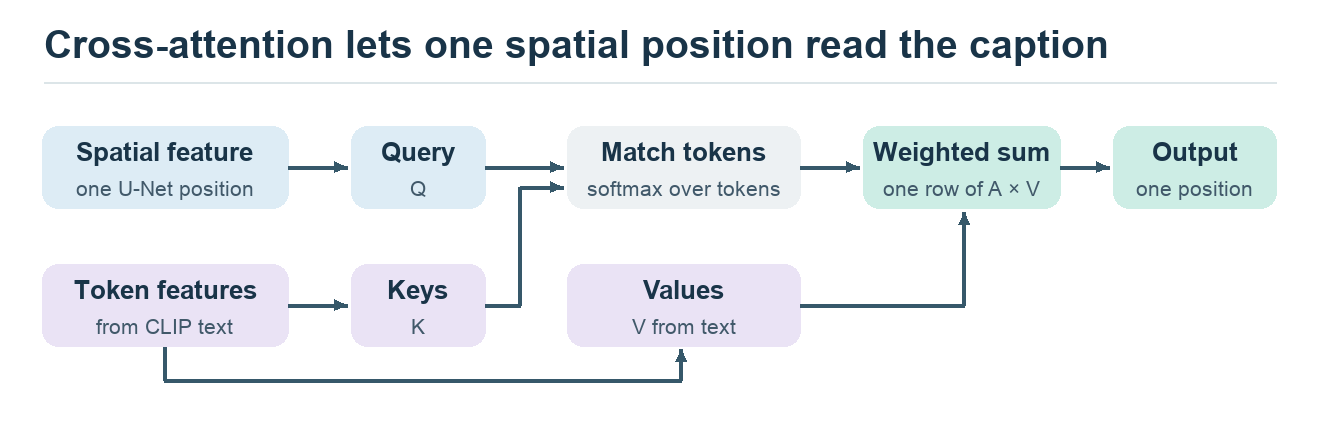

Flatten an intermediate feature map into $N=H W$ spatial vectors $F$. Encode the caption into $L=77$ token positions (including padding), with 768 features per position for SD 1.5. For one attention head,

$$Q=F W_Q,\quad K=h W_K,\quad V=h W_V,\qquad
A=\operatorname{softmax}_{\rm tokens}\!\left(\frac{QK^\top}{\sqrt d}\right),\qquad O=A V.$$

Read one row of $A\in\mathbb R^{N\times L}$: for one spatial position, its weights across text tokens sum to one. A position on the teapot can use color and material cues from multiple tokens. In self-attention the keys and values also come from spatial features. In cross-attention they come from the text sequence. CLIP's image encoder is unnecessary in this sampling path.

[Rombach et al., §3.3](https://arxiv.org/abs/2112.10752)

### Inspect the two conditioning tensors
Our prompt asks for a red teapot on a wooden table. Predict the shape of the conditioning before running the cell. The first batch entry encodes the empty caption and the second encodes the requested scene. Each spatial location in a cross-attention block can read these token features.

In [2]:
prompt = "a studio photograph of a red ceramic teapot on a wooden table, soft daylight"
seed = 42
@torch.inference_mode()
def encode(caption):
    ids = tokenizer(["", caption], padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids
    return text_encoder(ids.to(device)).last_hidden_state

def fixed_noise(seed, shape):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return torch.randn(shape, generator=generator).to(device=device, dtype=dtype)

initial = fixed_noise(seed, (1, 4, 64, 64))
print("Text features:", tuple(encode(prompt).shape), "| initial latent:", tuple(initial.shape))

Text features: (2, 77, 768) | initial latent: (1, 4, 64, 64)


## From one DDIM step to an image

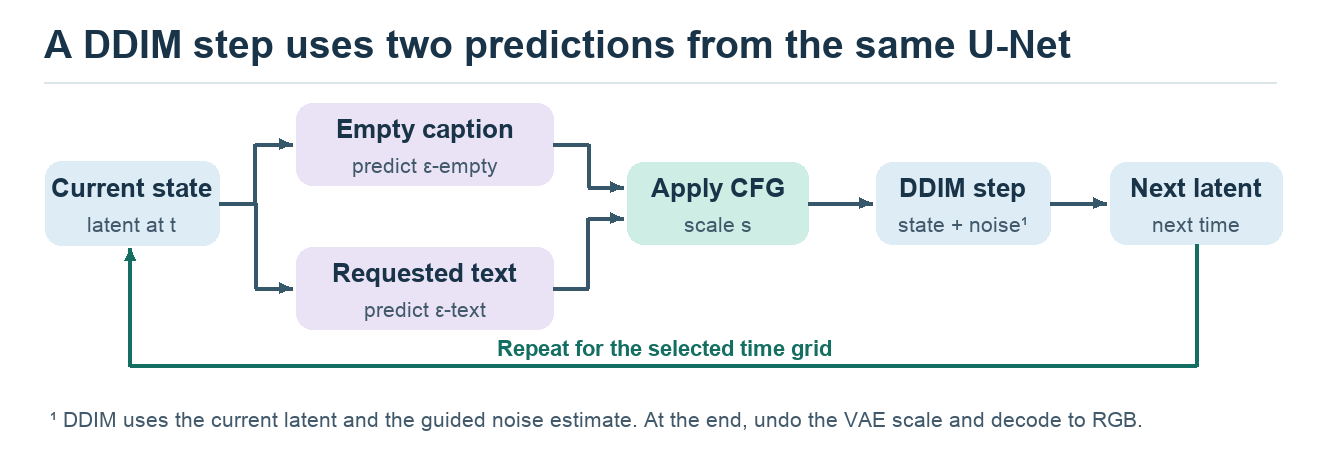


1. Encode the empty caption and the requested caption once. Draw $z_T\sim\mathcal N(0,I)$.
2. At time $t$, pass the same $z_t$ to both branches of the U-Net. Combine their predictions with $\hat\epsilon_s=\epsilon_\varnothing+s(\epsilon_c-\epsilon_\varnothing)$.
3. Pass $z_t$, $t$ and $\hat\epsilon_s$ to the scheduler. Its update gives the next latent on the chosen time grid. Repeat until the end.
4. Undo the scale and decode $D(z_0/k)$ to RGB.

**Connection to Imagen.** Pixel values have a display range. SD's four latent channels are learned coordinates with their own scale. Applying Imagen's pixel threshold directly to this grid would alter the denoiser's state. Below, the DDIM scheduler uses the checkpoint configuration with latent clipping disabled.

[Diffusers pipeline walkthrough](https://huggingface.co/docs/diffusers/using-diffusers/write_own_pipeline)

In the loop below, compare `update.prev_sample` (the state passed to the next step) with `update.pred_original_sample` (the clean-latent estimate decoded for each preview).

In [3]:
@torch.inference_mode()
def decode(z):
    rgb = vae.decode(z / vae.config.scaling_factor).sample
    pixels = ((rgb[0].float().clamp(-1, 1) + 1) * 127.5).round().byte()
    return Image.fromarray(pixels.permute(1, 2, 0).cpu().numpy())

@torch.inference_mode()
def denoise(start, caption, scale, timesteps, capture=()):
    context = encode(caption)
    z = start.clone()
    snapshots = []
    for step, t in enumerate(timesteps, start=1):
        inputs = scheduler.scale_model_input(torch.cat([z, z]), t)
        eps_empty, eps_text = unet(inputs, t, encoder_hidden_states=context).sample.chunk(2)
        eps = eps_empty + scale * (eps_text - eps_empty)
        update = scheduler.step(eps, t, z, eta=0)
        if step in capture:
            snapshots.append((f"step {step} / {len(timesteps)}", decode(update.pred_original_sample)))
        z = update.prev_sample
    return decode(z), snapshots

def generate(caption, scale=7.5, steps=20, capture=()):
    scheduler.set_timesteps(steps, device=device)
    return denoise(initial * scheduler.init_noise_sigma, caption, scale, scheduler.timesteps, capture)

def show_row(items):
    side = min(320, 1024 // len(items))
    row = Image.new("RGB", (side * len(items), side + 32), "white")
    draw = ImageDraw.Draw(row)
    for i, (label, image) in enumerate(items):
        row.paste(image.resize((side, side), Image.Resampling.LANCZOS), (i * side, 30))
        draw.text((i * side + 8, 8), label, fill="#183047")
    display(row)

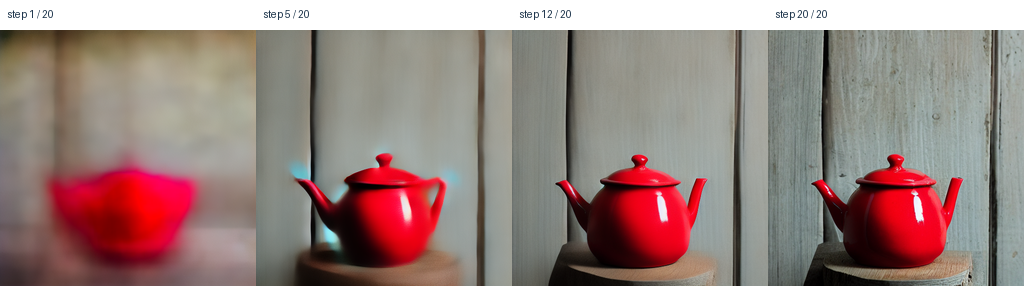

In [4]:
baseline, snapshots = generate(prompt, capture=(1, 5, 12, 20))
show_row(snapshots)

**Read the strip from left to right.** Each panel shows the current guess of the finished image. Find the earliest panel where you can identify the object, then track its handle, surface and shadow. The full-resolution final sample is stored in `baseline`.

In the saved run, a blurred red region is visible at step 1. The lid and spout can already be distinguished at step 5. By step 20 the grain of the wood behind the pot is visible.

## Compare guidance and step count
First keep 20 DDIM steps and vary $s$. At $s=1$ the combined prediction equals the conditional prediction. Then keep $s=7.5$ and compare 6 versus 20 steps. Both comparisons reuse exactly the same noise tensor and caption. Inspect the red glaze, the outline and the contact shadow.

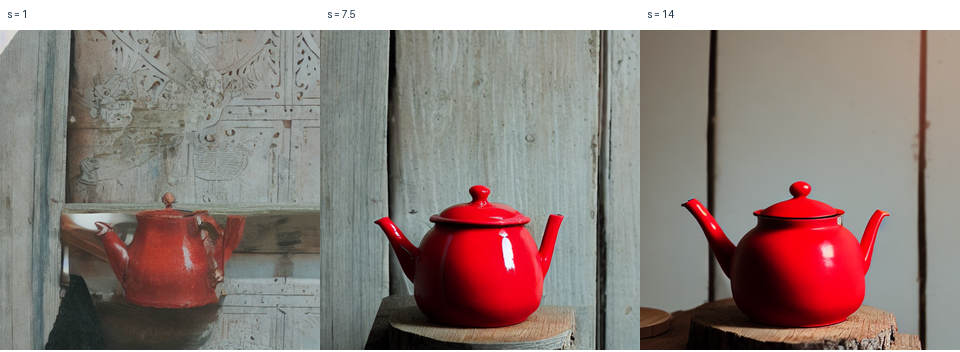

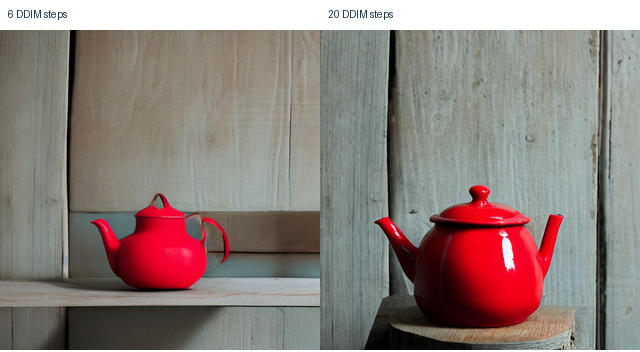

In [5]:
ordinary, _ = generate(prompt, scale=1)
strong, _ = generate(prompt, scale=14)
show_row([("s = 1", ordinary), ("s = 7.5", baseline), ("s = 14", strong)])
coarse, _ = generate(prompt, steps=6)
show_row([("6 DDIM steps", coarse), ("20 DDIM steps", baseline)])

Which setting best conveys “red ceramic”? Where can you still see texture? Check the handle and spout before judging the whole scene. To test consistency across seeds, change `seed`, recreate `initial` and rerun the trajectory and both comparisons.

In the saved comparison, the pot nearly blends into the wall at $s=1$. At $s=14$ it stands out against a smoother background. The six-step sample also places a smaller pot lower in the frame than the twenty-step sample.

## Edit the generated photo with img2img

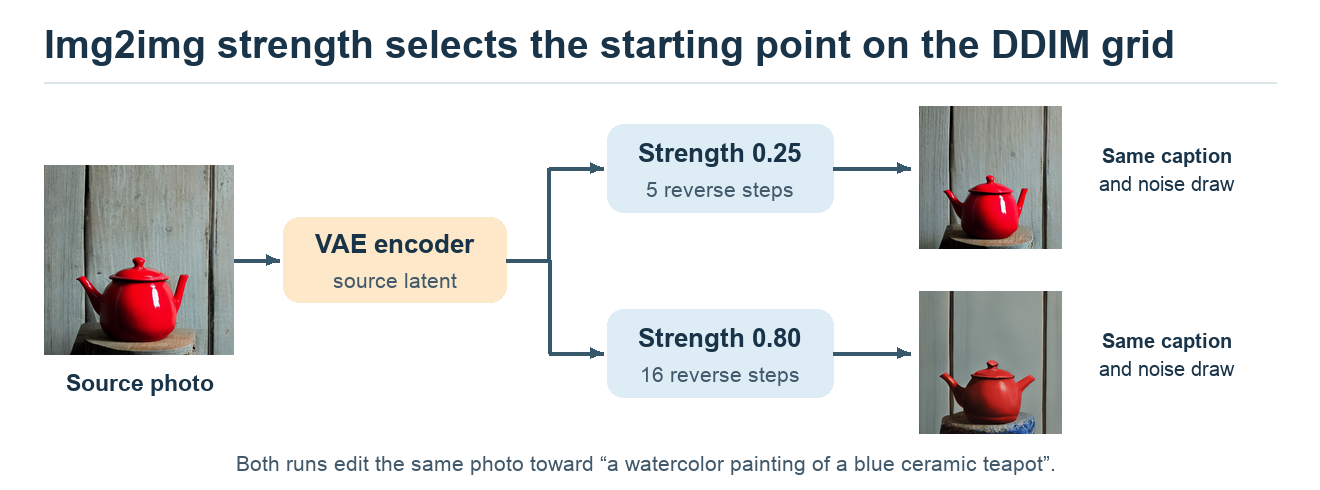

Start with a photograph we want to edit. Encode it to $z_{\rm src}$ and pick a time on the DDIM grid. Form $z_t=\sqrt{\bar\alpha_t}\,z_{\rm src}+\sqrt{1-\bar\alpha_t}\,\epsilon$. Run the remaining reverse steps with a new caption, then decode.

| Control | Where it acts | What to inspect in the lab |
|---|---|---|
| Guidance scale $s$ | Relative contribution of the caption at each denoising step | Is the teapot red? Are its texture and shadow still plausible? |
| Number of steps | Discretization of the reverse path | Does the handle meet the body? Is the spout coherent? |
| Img2img strength | Starting noise level and remaining length of the reverse path | Is the silhouette preserved when changing a photo into a watercolor? |

### Inspect the VAE reconstruction first
Encode the baseline photo, then use its posterior mode so VAE encoding is deterministic. Compare its reconstruction with the original first. Any difference here already exists before diffusion editing.

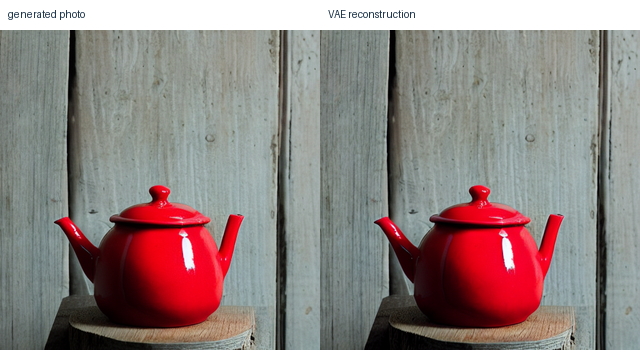

In [6]:
import numpy as np

@torch.inference_mode()
def encode_image(image):
    pixels = torch.from_numpy(np.asarray(image.convert("RGB")).copy())
    pixels = (pixels.permute(2, 0, 1).unsqueeze(0).float() / 127.5 - 1).to(device, dtype)
    return vae.encode(pixels).latent_dist.mode() * vae.config.scaling_factor

source_z = encode_image(baseline)
show_row([("generated photo", baseline), ("VAE reconstruction", decode(source_z))])

A strength of $k/N$ starts the editor with $k$ reverse updates remaining on our $N$-step grid. At the selected time add noise using $z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\epsilon$. Both edits share the same source, target caption, noise draw, schedule and CFG scale. A larger strength couples a noisier start with more reverse updates.

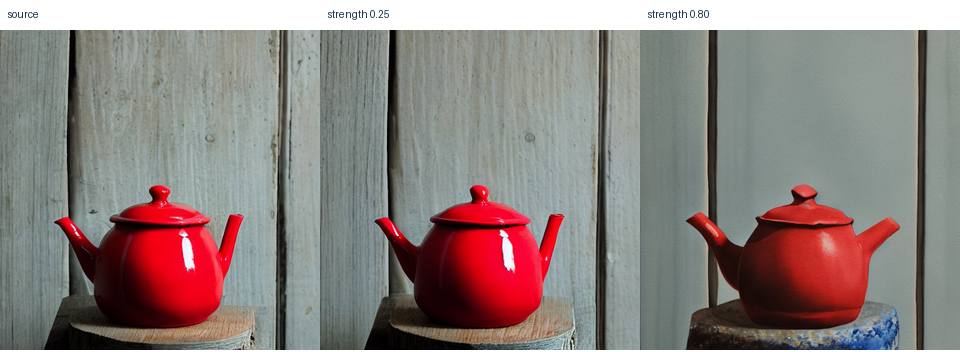

In [7]:
edit_caption = "a watercolor painting of a blue ceramic teapot on paper, loose brush strokes"
edit_noise = fixed_noise(seed + 1, source_z.shape)

def edit(strength, steps=20):
    scheduler.set_timesteps(steps, device=device)
    count = min(int(steps * strength), steps)
    if count < 1 or not 0 < strength <= 1:
        raise ValueError("Choose strength in [1 / steps, 1].")
    remaining = scheduler.timesteps[-count:]
    noisy = scheduler.add_noise(source_z, edit_noise, remaining[:1])
    result, _ = denoise(noisy, edit_caption, 7.5, remaining)
    return result

show_row([("source", baseline), ("strength 0.25", edit(0.25)), ("strength 0.80", edit(0.8))])

**Discuss.** Trace the outline of the source teapot in each edit. Which version retains its position? Which follows the requested color and medium? Explain separately what `strength` changes at initialization and what guidance changes inside every U-Net step.

In the saved run, the 0.25 edit keeps the source nearly intact. At 0.80 the spout and surface change, yet the pot stays red despite the request for blue. Try a second seed before generalizing about color control.

[SD 1.5 weights and model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) · [Diffusers walkthrough](https://huggingface.co/docs/diffusers/using-diffusers/write_own_pipeline) · [Previous YSDA playground](https://github.com/r-isachenko/2025-DGM-MIPT-YSDA-course/blob/main/seminars/seminar11/seminar11_SD.ipynb)